In [3]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"tanvirameshbhosale04","key":"7a5ef8da128592b23039de1cdc3d142b"}'}

In [4]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [5]:
!kaggle datasets download -d masoudnickparvar/brain-tumor-mri-dataset

Dataset URL: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
100% 157M/157M [00:04<00:00, 37.2MB/s]



In [6]:
!unzip -q brain-tumor-mri-dataset.zip

In [7]:
!ls

brain-tumor-mri-dataset.zip  kaggle.json  sample_data  Testing	Training


In [8]:
import os

train_path = "/content/Training"
test_path = "/content/Testing"

for folder in os.listdir(train_path):
    print(folder, ":", len(os.listdir(os.path.join(train_path, folder))))

glioma : 1400
notumor : 1400
pituitary : 1400
meningioma : 1400


In [9]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = (224,224)
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_generator = train_datagen.flow_from_directory(
    "/content/Training",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training'
)

val_generator = train_datagen.flow_from_directory(
    "/content/Training",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation'
)

test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_directory(
    "/content/Testing",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

Found 4480 images belonging to 4 classes.
Found 1120 images belonging to 4 classes.
Found 1600 images belonging to 4 classes.


In [10]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense, Dropout

cnn_model = Sequential([

    Conv2D(32, (3,3), activation='relu', input_shape=(224,224,3)),
    MaxPooling2D(2,2),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Flatten(),

    Dense(256, activation='relu'),
    Dropout(0.5),

    Dense(4, activation='softmax')
])

cnn_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

cnn_model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    22,151,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,245,700 (84.86 MB)

 Trainable params: 22,245,700 (84.86 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
history_cnn = cnn_model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10
)

Epoch 1/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 24s 113ms/step - accuracy: 0.7018 - loss: 0.7991 - val_accuracy: 0.8009 - val_loss: 0.5126
Epoch 2/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 95ms/step - accuracy: 0.8583 - loss: 0.4049 - val_accuracy: 0.8696 - val_loss: 0.3649
Epoch 3/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 98ms/step - accuracy: 0.8993 - loss: 0.2845 - val_accuracy: 0.8679 - val_loss: 0.3225
Epoch 4/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 93ms/step - accuracy: 0.9295 - loss: 0.2096 - val_accuracy: 0.9018 - val_loss: 0.2687
Epoch 5/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 93ms/step - accuracy: 0.9502 - loss: 0.1493 - val_accuracy: 0.9205 - val_loss: 0.2383
Epoch 6/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 94ms/step - accuracy: 0.9612 - loss: 0.1042 - val_accuracy: 0.9161 - val_loss: 0.2645
Epoch 7/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 95ms/step - accuracy: 0.9717 - loss: 0.0817 - val_accuracy: 0.9232 - val_loss: 0.2804
Epoch 8/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 95ms/step - accuracy: 0.9661 - loss: 0.1004 -

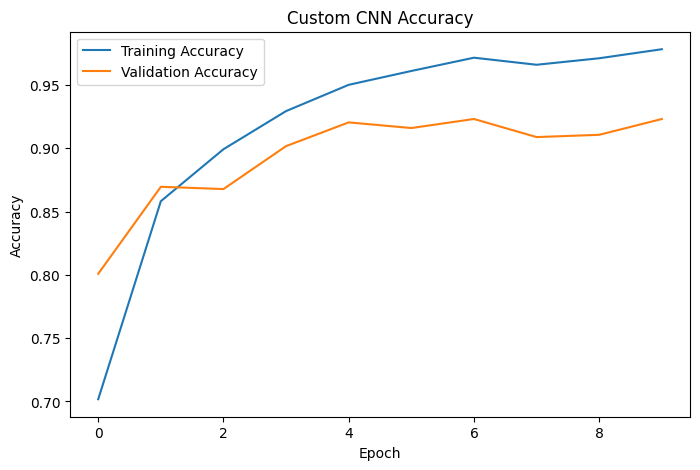

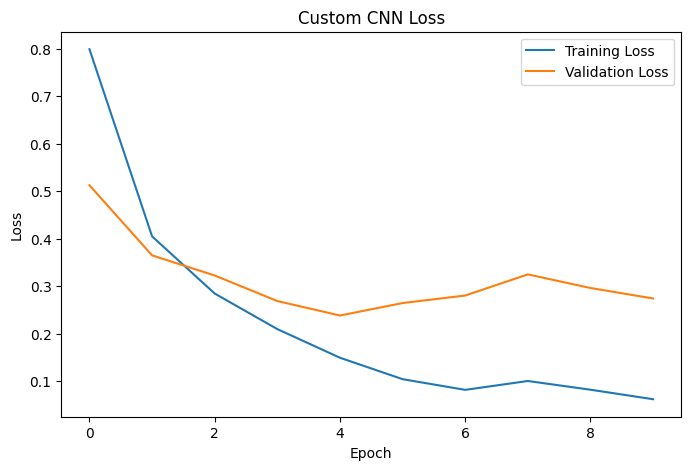

In [12]:
import matplotlib.pyplot as plt

# Accuracy
plt.figure(figsize=(8,5))
plt.plot(history_cnn.history['accuracy'], label='Training Accuracy')
plt.plot(history_cnn.history['val_accuracy'], label='Validation Accuracy')
plt.title('Custom CNN Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Loss
plt.figure(figsize=(8,5))
plt.plot(history_cnn.history['loss'], label='Training Loss')
plt.plot(history_cnn.history['val_loss'], label='Validation Loss')
plt.title('Custom CNN Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [13]:
loss, accuracy = cnn_model.evaluate(test_generator)

print("Test Accuracy:", accuracy)
print("Test Loss:", loss)

50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 78ms/step - accuracy: 0.8519 - loss: 1.4369
Test Accuracy: 0.8518750071525574
Test Loss: 1.4368600845336914


In [14]:
import numpy as np
from sklearn.metrics import classification_report

predictions = cnn_model.predict(test_generator)

y_pred = np.argmax(predictions, axis=1)

print(
    classification_report(
        test_generator.classes,
        y_pred,
        target_names=list(test_generator.class_indices.keys())
    )
)

50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 62ms/step
              precision    recall  f1-score   support

      glioma       0.92      0.70      0.80       400
  meningioma       0.77      0.81      0.79       400
     notumor       0.78      1.00      0.88       400
   pituitary       0.98      0.90      0.94       400

    accuracy                           0.85      1600
   macro avg       0.87      0.85      0.85      1600
weighted avg       0.87      0.85      0.85      1600



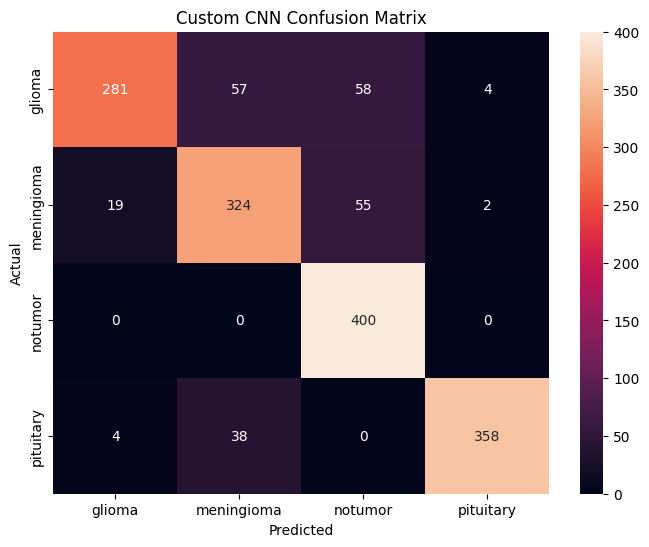

In [15]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(
    test_generator.classes,
    y_pred
)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=list(test_generator.class_indices.keys()),
            yticklabels=list(test_generator.class_indices.keys()))

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Custom CNN Confusion Matrix")
plt.show()

In [16]:
import os

glioma_folder = "/content/Testing/glioma"

print(os.listdir(glioma_folder)[:5])

['Te-gl_62.jpg', 'Te-gl_356.jpg', 'Te-gl_190.jpg', 'Te-gl_45.jpg', 'Te-gl_219.jpg']


Selected Image: Te-gl_90.jpg


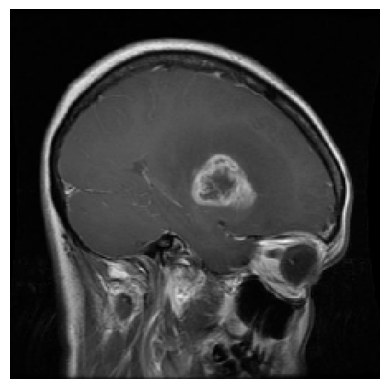

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 857ms/step
Actual Class: glioma
Predicted Class: glioma
Confidence: 99.82%


In [17]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing import image

# Pick a random image from the glioma folder
glioma_folder = "/content/Testing/glioma"

random_image = random.choice(os.listdir(glioma_folder))
img_path = os.path.join(glioma_folder, random_image)

print("Selected Image:", random_image)

# Load and display image
img = image.load_img(img_path, target_size=(224,224))

plt.imshow(img)
plt.axis('off')
plt.show()

# Prepare image for prediction
img_array = image.img_to_array(img)
img_array = img_array / 255.0
img_array = np.expand_dims(img_array, axis=0)

# Predict
prediction = cnn_model.predict(img_array)

classes = ['glioma','meningioma','notumor','pituitary']

predicted_class = classes[np.argmax(prediction)]
confidence = np.max(prediction) * 100

print("Actual Class: glioma")
print("Predicted Class:", predicted_class)
print(f"Confidence: {confidence:.2f}%")

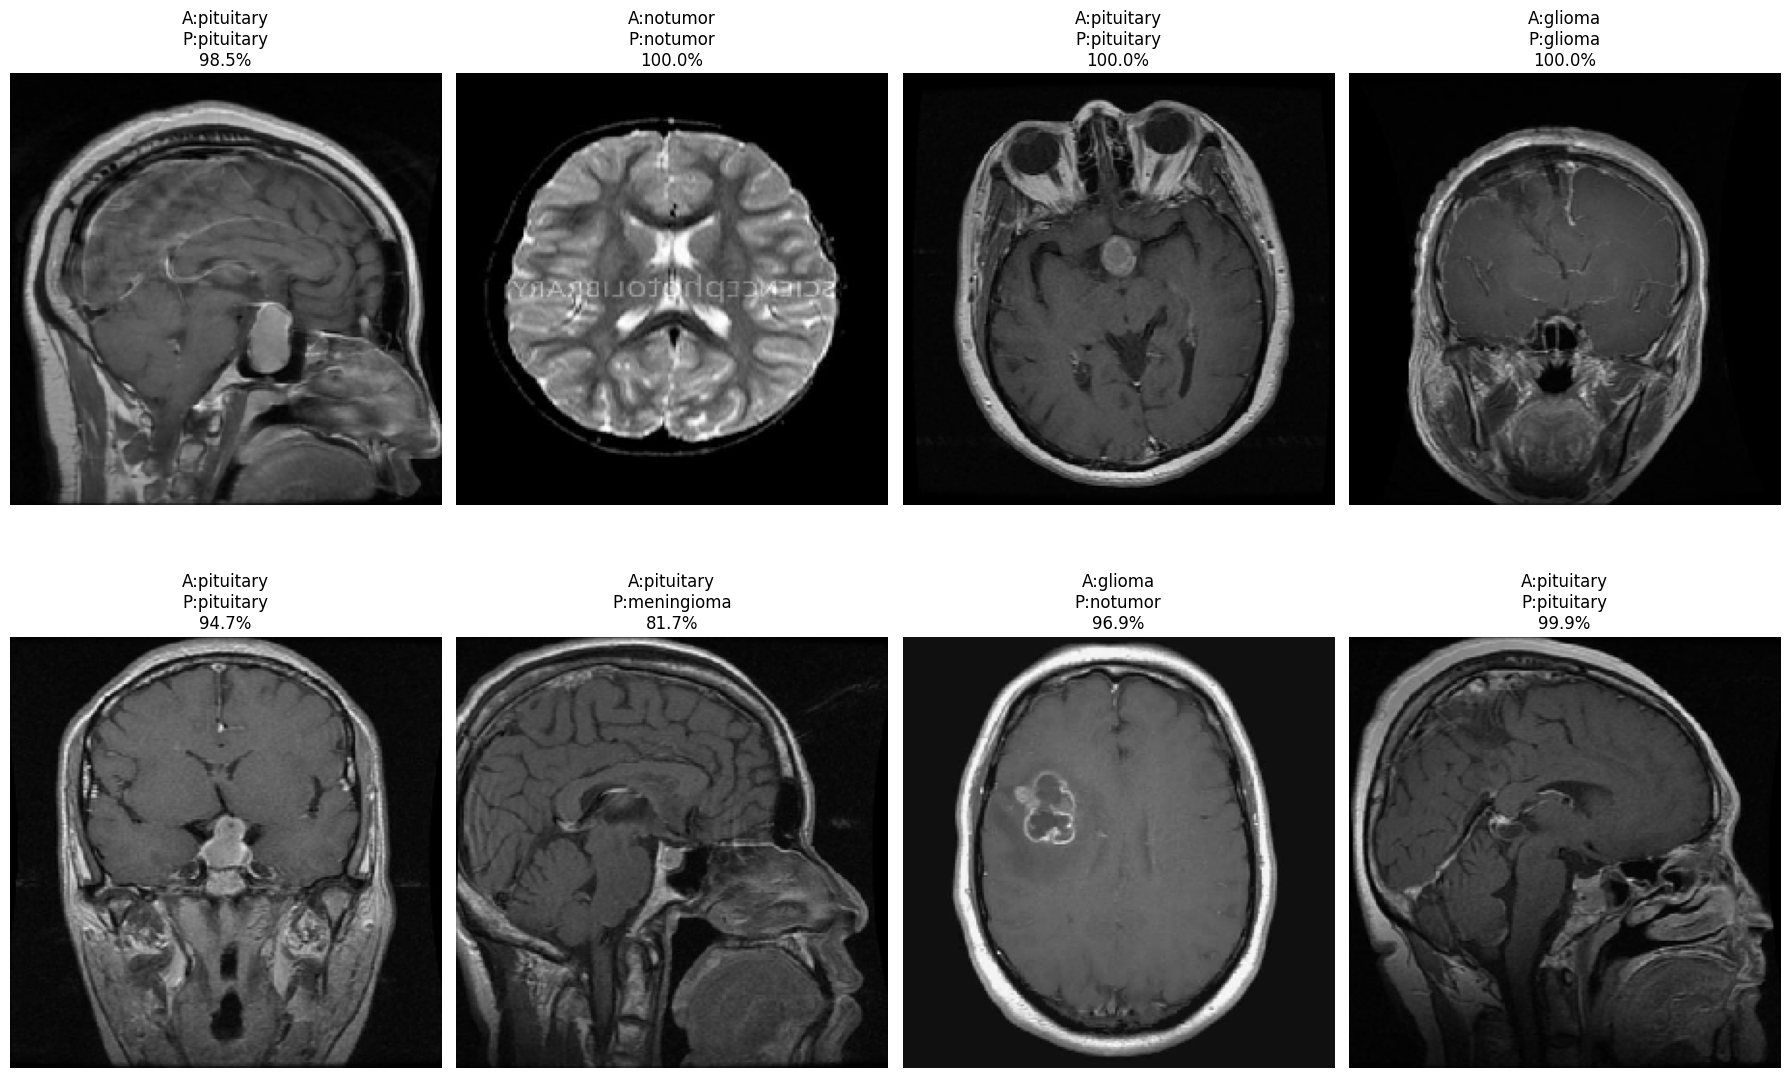

In [18]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image

classes = ['glioma', 'meningioma', 'notumor', 'pituitary']

plt.figure(figsize=(18,12))

for i in range(8):

    actual_class = random.choice(classes)

    folder = f"/content/Testing/{actual_class}"

    img_name = random.choice(os.listdir(folder))
    img_path = os.path.join(folder, img_name)

    img = image.load_img(img_path, target_size=(224,224))

    img_array = image.img_to_array(img)
    img_array = img_array / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    prediction = cnn_model.predict(img_array, verbose=0)

    predicted_class = classes[np.argmax(prediction)]
    confidence = np.max(prediction) * 100

    plt.subplot(2,4,i+1)
    plt.imshow(img)
    plt.axis('off')

    plt.title(
        f"A:{actual_class}\nP:{predicted_class}\n{confidence:.1f}%"
    )

plt.tight_layout()
plt.show()

In [19]:
import numpy as np
from tensorflow.keras.preprocessing import image

# Use the same image path you tested before
img_path = "/content/Testing/glioma/Te-gl_173.jpg"

img = image.load_img(img_path, target_size=(224,224))
img_array = image.img_to_array(img)
img_array = img_array / 255.0
img_array = np.expand_dims(img_array, axis=0)

prediction = cnn_model.predict(img_array, verbose=0)

classes = ['glioma', 'meningioma', 'notumor', 'pituitary']

for cls, prob in zip(classes, prediction[0]):
    print(f"{cls}: {prob*100:.2f}%")

glioma: 90.14%
meningioma: 9.66%
notumor: 0.00%
pituitary: 0.20%


In [20]:
import numpy as np
from tensorflow.keras.preprocessing import image

# Use the same image path you tested before
img_path = "/content/Testing/glioma/Te-gl_157.jpg"

img = image.load_img(img_path, target_size=(224,224))
img_array = image.img_to_array(img)
img_array = img_array / 255.0
img_array = np.expand_dims(img_array, axis=0)

prediction = cnn_model.predict(img_array, verbose=0)

classes = ['glioma', 'meningioma', 'notumor', 'pituitary']

for cls, prob in zip(classes, prediction[0]):
    print(f"{cls}: {prob*100:.2f}%")

glioma: 47.62%
meningioma: 52.33%
notumor: 0.04%
pituitary: 0.00%
